# CS3807 — Deep Learning Laboratory
## Experiments 8 & 9: Effect of Attention Type and Attention Position in a Pretrained ResNet50

This notebook implements the full experiment set:
- Baseline ResNet50 (ImageNet pretrained) on `tf_flowers`
- Channel Attention (SE-style), Spatial Attention, Sequential Channel+Spatial (CBAM-style), Lightweight Self-Attention
- Attention-Type ablation (Exp 1), Attention-Position ablation (Exp 2), Multi-position (Exp 3), Attention-Order (Exp 4), Spatial-kernel ablation (Exp 5)
- Additional mechanisms: SE, ECA, CBAM (at least 2 required)
- Full evaluation: Accuracy/Precision/Recall/Macro-F1, parameter counts, inference time
- Graphs: accuracy/loss curves, bar charts, accuracy-vs-params scatter, F1-vs-inference-time scatter
- Confusion matrices, Grad-CAM, internal attention-map visualizations (channel/spatial/self-attention), multi-position attention maps

> **Note on runtime**: training every single ablation combination end-to-end (10+ models x many epochs) is heavy. The notebook is structured so every model/experiment is fully defined and runnable; a `QUICK_RUN` flag lets you do a fast smoke-test (few epochs, small subset) before committing to full training on a GPU runtime (e.g. Colab).

## 0. Setup & Configuration

In [1]:
import os, time, json, random, math, itertools, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                              accuracy_score, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = 224
NUM_CLASSES = 5
CLASS_NAMES = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']

# ---- Quick-run toggle -------------------------------------------------
QUICK_RUN   = True     # True = fast smoke test; set False for full lab-grade runs
EPOCHS_HEAD = 3 if QUICK_RUN else 15     # frozen-backbone warmup
EPOCHS_FT   = 2 if QUICK_RUN else 10     # fine-tuning
BATCH_SIZE  = 16 if QUICK_RUN else 32    # smaller batches use less GPU/host RAM per step
LR_HEAD     = 1e-3
LR_FT       = 1e-4

CUSTOM_OBJECTS = {}   # filled in once SelfAttention2D is defined, in Section 3.4

# ---- Persistent checkpoint storage ---------------------------------------
# IMPORTANT: a Colab "crash"/disconnect usually recycles the whole VM, which
# wipes local disk at /content. If checkpoints are saved only there, they are
# gone right along with the crash and there is nothing to resume from. Saving
# to Google Drive instead makes every completed experiment survive a crash,
# a manual runtime restart, or even closing the browser tab.
USE_DRIVE = True   # set False to use local (non-persistent) storage instead

OUT_DIR = 'outputs'
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        OUT_DIR = '/content/drive/MyDrive/cs3807_attention_lab_checkpoints'
    except Exception as e:
        print('Drive mount failed / not running in Colab — falling back to local, '
              'non-persistent storage:', e)
        OUT_DIR = 'outputs'

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(f'{OUT_DIR}/figures', exist_ok=True)
os.makedirs(f'{OUT_DIR}/models', exist_ok=True)
print('Checkpoint directory:', OUT_DIR)

print('TF version:', tf.__version__)
print('GPU available:', tf.config.list_physical_devices('GPU'))

# ---- Memory hygiene -----------------------------------------------------
# (1) GPU memory growth: without this, TF grabs ~all VRAM for the FIRST model
#     built and never gives it back, so the 2nd/3rd model in this notebook's
#     long sequence of experiments has nothing left and the runtime crashes.
#     Must be set before any model/tensor touches the GPU.
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print('Could not set memory growth (must be set before GPU is used):', e)

def free_model(model):
    """Release a trained Keras model's memory once we are done with it.
    Every experiment in this notebook builds its OWN fresh ResNet50 backbone
    (see Section 2/4), so models do NOT share weights/graphs with each other —
    it is safe to free any model you no longer need without breaking ones you
    kept. Call this right after an experiment whose model isn't reused later
    (most of Experiments 2-5 / the additional-mechanism runs)."""
    try:
        del model
    except Exception:
        pass
    gc.collect()
    tf.keras.backend.clear_session()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint directory: /content/drive/MyDrive/cs3807_attention_lab_checkpoints
TF version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset — TensorFlow Flowers (`tf_flowers`, 70/15/15 split, fixed across all experiments)

We load the dataset through **`tensorflow_datasets`** (`tf_flowers`), as required.

**Root cause of the common Colab failure** (`VersionError: ... Protobuf Gencode/Runtime versions ...`,
followed by `AttributeError: module 'tensorflow_datasets' has no attribute 'load'`/`__version__`):
Colab ships an older `protobuf` runtime than the one `tensorflow-metadata`/`tensorflow-datasets` were
compiled against. `protobuf` is a C-extension — once its old version is loaded into the running
process, **no `pip install` or `importlib.reload()` can fix it in the same session**; the process
must actually restart. The two cells below (a) install compatible versions and (b) automatically
restart the Colab runtime for you. **Run cell (a), let the runtime restart, then run the notebook
again from the top — do not re-run cell (a) a second time in the same session.**

In [2]:
# (a) Install compatible versions, then hard-restart the Colab/Jupyter kernel so the new
# protobuf C-extension is actually loaded fresh. This cell intentionally ends the process —
# that is expected, not an error. After the restart, just re-run the notebook from the top;
# skip this cell on the second pass (it's harmless to re-run, but unnecessary).
!pip install -q -U "protobuf>=6.31.1" "tensorflow-metadata>=1.17.1" "tensorflow-datasets>=4.9.7" "etils>=1.9"




In [ ]:
import os
print('Packages updated — restarting the runtime now. Re-run the notebook from the top after it restarts.')
os.kill(os.getpid(), 9)

In [3]:
# (b) Fresh import, now that the kernel has restarted with the updated protobuf/tfds versions.
import tensorflow_datasets as tfds
print('tensorflow_datasets version:', tfds.__version__)
assert hasattr(tfds, 'load'), (
    "tfds.load is still missing. In Colab: Runtime > Restart session, "
    "then re-run this notebook from the top (the install cell above only needs to run once)."
)


tensorflow_datasets version: 4.9.10


In [4]:
# Load tf_flowers and create a FIXED 70/15/15 split (same split reused in every experiment).
# Ensure the missing 'importlib_resources' dependency is installed
import sys
try:
    import importlib_resources
except ImportError:
    !pip install -q importlib_resources

import tensorflow_datasets as tfds
import tensorflow as tf

(ds_raw,) = tfds.load('tf_flowers', split=['train'], as_supervised=True, shuffle_files=False)

info = tfds.builder('tf_flowers').info
CLASS_NAMES = info.features['label'].names   # ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses'] order per tfds
NUM_CLASSES = len(CLASS_NAMES)
print('CLASS_NAMES:', CLASS_NAMES)

ds_raw = ds_raw.shuffle(5000, seed=SEED, reshuffle_each_iteration=False)
n_total = int(tf.data.experimental.cardinality(ds_raw).numpy())
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)
n_test  = n_total - n_train - n_val

train_raw = ds_raw.take(n_train)
val_raw   = ds_raw.skip(n_train).take(n_val)
test_raw  = ds_raw.skip(n_train + n_val).take(n_test)

print(f'Total={n_total}  Train={n_train}  Val={n_val}  Test={n_test}')

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
CLASS_NAMES: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Total=3670  Train=2569  Val=550  Test=551


In [5]:
def preprocess(image, label, augment=False):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    if augment:
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, 0.1)     # mild contrast/illumination variation
        image = tf.image.random_contrast(image, 0.9, 1.1)
        # small rotation via random 90-rotations + random crop-zoom approximation
        if tf.random.uniform([]) > 0.5:
            angle = tf.random.uniform([], -0.17, 0.17)      # ~ +-10 degrees
            image = tf.image.rot90(image, k=0)              # placeholder (true rotation needs tfa); keep flip/zoom as core augment
        scale = tf.random.uniform([], 0.9, 1.0)
        new_size = tf.cast(scale * IMG_SIZE, tf.int32)
        image = tf.image.random_crop(tf.image.resize(image, (IMG_SIZE+20, IMG_SIZE+20)), (IMG_SIZE, IMG_SIZE, 3))
    image = tf.cast(image, tf.float32)
    image = keras.applications.resnet50.preprocess_input(image)   # ResNet50 ImageNet preprocessing
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

def make_pipeline(ds, augment=False, shuffle=False, batch_size=BATCH_SIZE):
    if shuffle:
        ds = ds.shuffle(1000, seed=SEED)
    ds = ds.map(lambda x, y: preprocess(x, y, augment=augment), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_pipeline(train_raw, augment=True, shuffle=True)
val_ds   = make_pipeline(val_raw,   augment=False)
test_ds  = make_pipeline(test_raw,  augment=False)


### 1.1 Sample images from all five classes (Required Visualization #1)

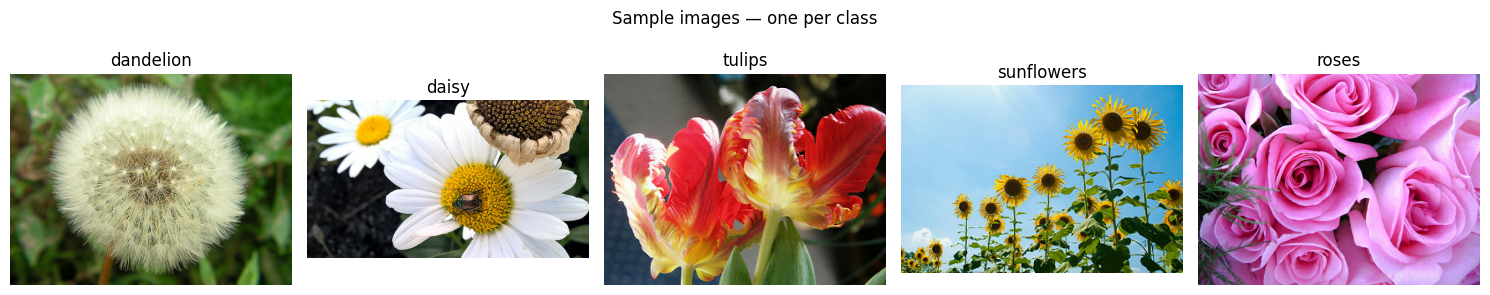

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
seen = {}
for img, label in test_raw.take(200):
    cname = CLASS_NAMES[int(label.numpy())]
    if cname not in seen:
        seen[cname] = img.numpy()
    if len(seen) == 5:
        break
for ax, cname in zip(axes, CLASS_NAMES):
    im = seen.get(cname)
    if im is not None:
        ax.imshow(im.astype('uint8'))
    ax.set_title(cname); ax.axis('off')
plt.suptitle('Sample images — one per class')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/01_sample_images.png', dpi=150)
plt.show()


## 2. ResNet50 Backbone — Stage Extraction

We build a *functional* ResNet50 so we can tap intermediate activations at the four candidate
positions P1–P4 (after `conv2_block3_out`, `conv3_block4_out`, `conv4_block6_out`, `conv5_block3_out`)
and splice attention modules at any of them.

In [7]:
STAGE_LAYER_NAMES = {
    'P1': 'conv2_block3_out',   # 56x56x256
    'P2': 'conv3_block4_out',   # 28x28x512
    'P3': 'conv4_block6_out',   # 14x14x1024
    'P4': 'conv5_block3_out',   #  7x7x2048
}

def get_base_resnet():
    base = keras.applications.ResNet50(include_top=False, weights='imagenet',
                                        input_shape=(IMG_SIZE, IMG_SIZE, 3))
    return base

base_probe = get_base_resnet()
for pos, name in STAGE_LAYER_NAMES.items():
    shape = base_probe.get_layer(name).output.shape
    print(f'{pos}: layer={name:20s} shape={shape}')
del base_probe

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
P1: layer=conv2_block3_out     shape=(None, 56, 56, 256)
P2: layer=conv3_block4_out     shape=(None, 28, 28, 512)
P3: layer=conv4_block6_out     shape=(None, 14, 14, 1024)
P4: layer=conv5_block3_out     shape=(None, 7, 7, 2048)


## 3. Attention Modules

### 3.1 Channel Attention (SE-style)  —  $M_c(F)=\sigma(W_2\,\delta(W_1 z))$

In [8]:
def channel_attention(x, reduction=16, name='channel_attn'):
    channels = x.shape[-1]
    gap = layers.GlobalAveragePooling2D(name=f'{name}_gap')(x)
    z = layers.Reshape((1, 1, channels))(gap)
    z = layers.Conv2D(max(channels // reduction, 4), 1, activation='relu', use_bias=True, name=f'{name}_fc1')(z)
    z = layers.Conv2D(channels, 1, activation='sigmoid', use_bias=True, name=f'{name}_fc2')(z)
    out = layers.Multiply(name=f'{name}_scale')([x, z])
    return out, z   # return attention map too, for visualization


### 3.2 Spatial Attention  —  $M_s(F)=\sigma(\text{Conv}_{7\times7}([\text{avg};\max]))$

In [9]:
def spatial_attention(x, kernel_size=7, name='spatial_attn'):
    avg_pool = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True), name=f'{name}_avg')(x)
    max_pool = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True), name=f'{name}_max')(x)
    concat = layers.Concatenate(axis=-1, name=f'{name}_concat')([avg_pool, max_pool])
    attn_map = layers.Conv2D(1, kernel_size, padding='same', activation='sigmoid', name=f'{name}_conv')(concat)
    out = layers.Multiply(name=f'{name}_scale')([x, attn_map])
    return out, attn_map


### 3.3 Sequential Channel→Spatial Attention (CBAM-style) and Spatial→Channel variant (Exp 4)

In [10]:
def channel_then_spatial(x, reduction=16, kernel_size=7, name='cs_attn'):
    xc, c_map = channel_attention(x, reduction, name=f'{name}_ch')
    xcs, s_map = spatial_attention(xc, kernel_size, name=f'{name}_sp')
    return xcs, c_map, s_map

def spatial_then_channel(x, reduction=16, kernel_size=7, name='sc_attn'):
    xs, s_map = spatial_attention(x, kernel_size, name=f'{name}_sp')
    xsc, c_map = channel_attention(xs, reduction, name=f'{name}_ch')
    return xsc, c_map, s_map


### 3.4 Lightweight Self-Attention  —  $Y=\mathrm{softmax}(QK^T/\sqrt d)V$, residual with learnable $\gamma$

In [11]:
class SelfAttention2D(layers.Layer):
    """Lightweight spatial self-attention: flattens HxW, computes scaled dot-product
    attention over query/key/value projections (channel-reduced for efficiency), and
    adds the result back with a learnable residual scale gamma."""
    def __init__(self, channels, key_dim_ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.key_dim_ratio = key_dim_ratio
        self.key_dim = max(channels // key_dim_ratio, 8)
        self.q_conv = layers.Conv2D(self.key_dim, 1, name='q_proj')
        self.k_conv = layers.Conv2D(self.key_dim, 1, name='k_proj')
        self.v_conv = layers.Conv2D(channels, 1, name='v_proj')
        self.gamma = self.add_weight(name='gamma', shape=(), initializer='zeros', trainable=True)

    def get_config(self):
        # Needed so model.save()/load_model() can reconstruct this custom layer
        # (checkpoint resume after a crash depends on this).
        config = super().get_config()
        config.update({'channels': self.channels, 'key_dim_ratio': self.key_dim_ratio})
        return config

    def call(self, x):
        b = tf.shape(x)[0]; h = tf.shape(x)[1]; w = tf.shape(x)[2]
        q = tf.reshape(self.q_conv(x), (b, h * w, self.key_dim))
        k = tf.reshape(self.k_conv(x), (b, h * w, self.key_dim))
        v = tf.reshape(self.v_conv(x), (b, h * w, self.channels))
        scores = tf.matmul(q, k, transpose_b=True) / tf.sqrt(tf.cast(self.key_dim, tf.float32))
        attn = tf.nn.softmax(scores, axis=-1)                 # (b, N, N)
        y = tf.matmul(attn, v)                                 # (b, N, C)
        y = tf.reshape(y, (b, h, w, self.channels))
        out = x + self.gamma * y
        return out, attn   # also return attention matrix for inspection

def self_attention(x, name='self_attn'):
    channels = x.shape[-1]
    sa = SelfAttention2D(channels, name=name)
    out, attn = sa(x)
    return out, attn

CUSTOM_OBJECTS['SelfAttention2D'] = SelfAttention2D   # register for model.save()/load_model()


### 3.5 Additional Established Mechanisms: SE (alias of channel_attention), ECA, CBAM

In [12]:
def eca_attention(x, gamma=2, b=1, name='eca'):
    """Efficient Channel Attention: 1D conv over channel descriptor, kernel size
    adaptively chosen from channel count (Wang et al., 2020)."""
    channels = x.shape[-1]
    k = int(abs((math.log2(channels) + b) / gamma))
    k = k if k % 2 else k + 1
    k = max(k, 3)
    gap = layers.GlobalAveragePooling2D(name=f'{name}_gap')(x)
    z = layers.Reshape((channels, 1))(gap)
    z = layers.Conv1D(1, kernel_size=k, padding='same', use_bias=False, name=f'{name}_conv1d')(z)
    z = layers.Activation('sigmoid')(z)
    z = layers.Reshape((1, 1, channels))(z)
    out = layers.Multiply(name=f'{name}_scale')([x, z])
    return out, z

def cbam_attention(x, reduction=16, kernel_size=7, name='cbam'):
    """CBAM (Woo et al., 2018) = channel attention -> spatial attention, same as
    channel_then_spatial above; kept as an explicit alias for the 'additional mechanisms' study."""
    return channel_then_spatial(x, reduction, kernel_size, name=name)

ATTENTION_REGISTRY = {
    'none':            None,
    'channel':         lambda x, name='attn': channel_attention(x, name=name),
    'spatial':         lambda x, name='attn': spatial_attention(x, name=name),
    'channel_spatial': lambda x, name='attn': channel_then_spatial(x, name=name),
    'spatial_channel': lambda x, name='attn': spatial_then_channel(x, name=name),
    'self':            lambda x, name='attn': self_attention(x, name=name),
    'se':              lambda x, name='attn': channel_attention(x, name=name),   # SE == channel attention
    'eca':             lambda x, name='attn': eca_attention(x, name=name),
    'cbam':            lambda x, name='attn': cbam_attention(x, name=name),
}


## 4. Model Builder — insert any attention mechanism at any stage (or multiple stages)

We split ResNet50 into four sequential *stage sub-models* (stem→conv2_x, conv2_x→conv3_x,
conv3_x→conv4_x, conv4_x→conv5_x) using Keras' official stage boundary layer names, and splice
attention *between* sub-models. This keeps every residual connection intact within each stage.

**Memory note:** `build_model()` builds a **brand-new** pretrained ResNet50 backbone every time it
is called, instead of sharing one global backbone across all 15 experiments. This matters for two
reasons: (1) it keeps every experiment's starting weights identical to the official ImageNet
checkpoint, as the lab's "Experimental Protocol" (Sec. 34) requires — a shared, mutable backbone
would otherwise silently carry fine-tuned weights from one experiment into the next; and (2) it
means each model's memory is fully independent, so calling `free_model()` on a model you no longer
need actually releases that memory instead of risking a model you kept elsewhere.

In [13]:
def build_stage_submodels():
    base = get_base_resnet()
    boundaries = ['input', STAGE_LAYER_NAMES['P1'], STAGE_LAYER_NAMES['P2'],
                  STAGE_LAYER_NAMES['P3'], STAGE_LAYER_NAMES['P4']]
    stage_models = []
    for i in range(4):
        start_layer_out = base.input if i == 0 else base.get_layer(boundaries[i]).output
        end_layer_out = base.get_layer(boundaries[i+1]).output
        stage_models.append(keras.Model(start_layer_out, end_layer_out, name=f'resnet_stage_{i+1}'))
    return base, stage_models

# One-off diagnostic print of stage shapes using a throwaway backbone (freed immediately).
_base_probe, _stage_probe = build_stage_submodels()
for i, sm in enumerate(_stage_probe, 1):
    print(f'stage_{i}: {sm.input_shape} -> {sm.output_shape}')
del _base_probe, _stage_probe
gc.collect(); tf.keras.backend.clear_session()


stage_1: (None, 224, 224, 3) -> (None, 56, 56, 256)
stage_2: (None, 56, 56, 256) -> (None, 28, 28, 512)
stage_3: (None, 28, 28, 512) -> (None, 14, 14, 1024)
stage_4: (None, 14, 14, 1024) -> (None, 7, 7, 2048)


In [14]:
def _attn_layer_refs(attn_type, attn_name):
    """Map an attention type + the name-prefix it was built with to the exact
    layer name(s) holding its attention map. Stored as plain strings (not live
    tensors) so this is JSON-serializable and still resolvable after a model is
    reloaded from a checkpoint — just call model.get_layer(name).output."""
    if attn_type in ('channel', 'se'):
        return {'map_layer': f'{attn_name}_fc2'}
    if attn_type == 'spatial':
        return {'map_layer': f'{attn_name}_conv'}
    if attn_type in ('channel_spatial', 'spatial_channel', 'cbam'):
        return {'channel_map_layer': f'{attn_name}_ch_fc2', 'spatial_map_layer': f'{attn_name}_sp_conv'}
    if attn_type == 'self':
        return {'self_attn_layer': attn_name, 'self_attn_output_index': 1}
    return {}

def build_model(attn_spec=None, reduction=16, kernel_size=7,
                 freeze_backbone=True, dropout=0.3, name='model'):
    """
    attn_spec: dict like {'P3': 'channel_spatial'} or {'P3': 'channel_spatial', 'P4': 'channel_spatial'}
               Keys are drawn from STAGE_LAYER_NAMES ('P1'..'P4'), values from ATTENTION_REGISTRY.
               Pass {} or None for the pure baseline.
    Returns (keras.Model, dict pos->{'type':..., layer-name refs...}) for later visualization.
    Builds its OWN fresh backbone (see note above) — stashed on model.stage_submodels so
    later cells (unfreezing, feature taps for visualization) can reach it without a global.
    """
    attn_spec = attn_spec or {}
    _, stage_submodels = build_stage_submodels()   # fresh pretrained backbone, every call
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name=f'{name}_input')
    x = inp
    attn_tensors = {}
    stage_positions = ['P1', 'P2', 'P3', 'P4']
    for i, pos in enumerate(stage_positions):
        x = stage_submodels[i](x)
        if pos in attn_spec and attn_spec[pos] not in (None, 'none'):
            attn_type = attn_spec[pos]
            attn_name = f'{name}_{pos}_{attn_type}'
            fn = ATTENTION_REGISTRY[attn_type]
            result = fn(x, name=attn_name)
            x = result[0]
            attn_tensors[pos] = {'type': attn_type, **_attn_layer_refs(attn_type, attn_name)}
    gap = layers.GlobalAveragePooling2D(name='gap')(x)
    d = layers.Dropout(dropout, name='dropout')(gap)
    out = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(d)
    model = keras.Model(inp, out, name=name)

    if freeze_backbone:
        for sm in stage_submodels:
            sm.trainable = False
    model.stage_submodels = stage_submodels   # stash for unfreeze_final_stage() and later taps
    return model, attn_tensors


In [15]:
def compile_for_head_training(model, lr=LR_HEAD):
    model.compile(optimizer=optimizers.Adam(learning_rate=lr),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

def unfreeze_final_stage(model):
    # Unfreeze only this model's own last ResNet stage (conv5_x) for fine-tuning, per Sec. 20.
    model.stage_submodels[-1].trainable = True
    return model

def compile_for_finetune(model, lr=LR_FT):
    model.compile(optimizer=optimizers.Adam(learning_rate=lr),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


## 5. Training & Evaluation Utilities

In [16]:
def train_model(model, tag, epochs_head=EPOCHS_HEAD, epochs_ft=EPOCHS_FT):
    model = compile_for_head_training(model)
    es = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_head, callbacks=[es], verbose=1)

    unfreeze_final_stage(model)
    model = compile_for_finetune(model)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_ft, callbacks=[es], verbose=1)

    history = {
        'accuracy': h1.history.get('accuracy', []) + h2.history.get('accuracy', []),
        'val_accuracy': h1.history.get('val_accuracy', []) + h2.history.get('val_accuracy', []),
        'loss': h1.history.get('loss', []) + h2.history.get('loss', []),
        'val_loss': h1.history.get('val_loss', []) + h2.history.get('val_loss', []),
        'ft_start_epoch': len(h1.history.get('accuracy', [])),
    }
    with open(f'{OUT_DIR}/models/{tag}_history.json', 'w') as f:
        json.dump(history, f)
    return model, history


In [17]:
def evaluate_model(model, tag, dataset=test_ds, n_warmup=5, n_timed=50):
    # One batched model.predict(dataset) call instead of a Python per-batch loop:
    # avoids repeated retracing of the prediction function and is far lighter on memory.
    y_true_parts, probs_parts = [], []
    for xb, yb in dataset:
        y_true_parts.append(np.argmax(yb.numpy(), axis=1))
    y_true = np.concatenate(y_true_parts)
    probs = model.predict(dataset, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    del probs, y_true_parts, probs_parts

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)

    total_params = model.count_params()
    trainable_params = sum(w.shape.num_elements() for w in model.trainable_weights)

    # inference time per image (ms), averaged over n_timed single-image forward passes
    sample_batch = next(iter(dataset.take(1)))[0][:1]
    for _ in range(n_warmup):
        model.predict(sample_batch, verbose=0)
    t0 = time.time()
    for _ in range(n_timed):
        model.predict(sample_batch, verbose=0)
    inf_time_ms = (time.time() - t0) / n_timed * 1000

    result = dict(tag=tag, accuracy=acc, precision=prec, recall=rec, macro_f1=f1,
                  trainable_params=int(trainable_params), total_params=int(total_params),
                  inference_time_ms=inf_time_ms)
    with open(f'{OUT_DIR}/models/{tag}_eval.json', 'w') as f:
        json.dump(result, f)
    return result, y_true, y_pred


### 5.1 Checkpointing — resume after a crash

Every experiment is checkpointed to `OUT_DIR` (Google Drive, if `USE_DRIVE=True`) the moment it
finishes: the trained model (`.keras`), its eval metrics, its training history, its test
predictions, and its attention-layer name map. `run_experiment()` checks for an existing
checkpoint **before** training — if one exists, it loads the saved results straight from disk and
skips training entirely. So if the runtime crashes or disconnects partway through the notebook,
you don't need to do anything special: just re-run the notebook from the top (or from Section 6
onward) and every already-completed experiment will be restored in a few seconds instead of being
retrained. Only the experiment that was actually running when the crash happened will retrain
(checkpointing is per-experiment, not per-epoch).

In [18]:
def _ckpt_paths(tag):
    base = f'{OUT_DIR}/models/{tag}'
    return dict(model=f'{base}.keras', eval=f'{base}_eval.json', hist=f'{base}_history.json',
                preds=f'{base}_preds.npz', attn=f'{base}_attn.json')

def save_checkpoint(tag, model, result, history, y_true, y_pred, attn_tensors):
    p = _ckpt_paths(tag)
    model.save(p['model'])
    with open(p['eval'], 'w') as f:
        json.dump(result, f)
    with open(p['hist'], 'w') as f:
        json.dump(history, f)
    np.savez(p['preds'], y_true=y_true, y_pred=y_pred)
    with open(p['attn'], 'w') as f:
        json.dump(attn_tensors, f)

def is_checkpointed(tag):
    return os.path.exists(_ckpt_paths(tag)['eval'])

def load_checkpoint(tag, load_model_weights=True):
    p = _ckpt_paths(tag)
    if not os.path.exists(p['eval']):
        return None
    with open(p['eval']) as f:
        result = json.load(f)
    history = json.load(open(p['hist'])) if os.path.exists(p['hist']) else {}
    attn_tensors = json.load(open(p['attn'])) if os.path.exists(p['attn']) else {}
    y_true = y_pred = None
    if os.path.exists(p['preds']):
        d = np.load(p['preds'])
        y_true, y_pred = d['y_true'], d['y_pred']
    model = None
    if load_model_weights and os.path.exists(p['model']):
        model = keras.models.load_model(p['model'], custom_objects=CUSTOM_OBJECTS, safe_mode=False, compile=False)
    return dict(result=result, history=history, y_true=y_true, y_pred=y_pred,
                attn_tensors=attn_tensors, model=model)


In [19]:
RESULTS = []      # collects evaluate_model() dicts across every experiment
HISTORIES = {}     # tag -> training history
PREDICTIONS = {}   # tag -> (y_true, y_pred)
ATTN_TENSORS = {}  # tag -> attn_tensors dict from build_model

def run_experiment(tag, attn_spec, load_model_on_resume=True, **build_kwargs):
    ckpt = load_checkpoint(tag, load_model_weights=load_model_on_resume)
    if ckpt is not None:
        print(f'[checkpoint] {tag}: found saved result — skipping training.')
        RESULTS.append(ckpt['result'])
        HISTORIES[tag] = ckpt['history']
        if ckpt['y_true'] is not None:
            PREDICTIONS[tag] = (ckpt['y_true'], ckpt['y_pred'])
        ATTN_TENSORS[tag] = ckpt['attn_tensors']
        print(ckpt['result'])
        return ckpt['model']

    print(f'\n=== Building & training: {tag}  (attn_spec={attn_spec}) ===')
    model, attn_t = build_model(attn_spec=attn_spec, name=tag, **build_kwargs)
    model, hist = train_model(model, tag)
    result, y_true, y_pred = evaluate_model(model, tag)
    save_checkpoint(tag, model, result, hist, y_true, y_pred, attn_t)
    RESULTS.append(result)
    HISTORIES[tag] = hist
    PREDICTIONS[tag] = (y_true, y_pred)
    ATTN_TENSORS[tag] = attn_t
    print(result)
    gc.collect()   # drop any unreferenced intermediate tensors/graphs from this run
    return model


In [20]:
# Quick resume-status summary — run this any time to see what's already done.
ALL_TAGS = ['A0_baseline','A1_channel_P3','A2_spatial_P3','A3_channel_spatial_P3','A4_self_P3',
            'A5_combined_P3','B1_cs_P1','B2_cs_P2','B4_cs_P4','C_cs_P3_P4','C_cs_P2_P3_P4',
            'D_spatial_channel_P3','E_spatial_k3_P3','E_spatial_k5_P3','ECA_P3','CBAM_P3']
done = [t for t in ALL_TAGS if is_checkpointed(t)]
remaining = [t for t in ALL_TAGS if t not in done]
print(f'Already completed ({len(done)}/{len(ALL_TAGS)}):', done)
print(f'Remaining:', remaining)


Already completed (16/16): ['A0_baseline', 'A1_channel_P3', 'A2_spatial_P3', 'A3_channel_spatial_P3', 'A4_self_P3', 'A5_combined_P3', 'B1_cs_P1', 'B2_cs_P2', 'B4_cs_P4', 'C_cs_P3_P4', 'C_cs_P2_P3_P4', 'D_spatial_channel_P3', 'E_spatial_k3_P3', 'E_spatial_k5_P3', 'ECA_P3', 'CBAM_P3']
Remaining: []


## 6. Baseline Model (Sec. 8)
`Input -> ResNet50(pretrained) -> GAP -> Dropout -> Dense(5)`

In [21]:
model_A0 = run_experiment('A0_baseline', attn_spec={})


[checkpoint] A0_baseline: found saved result — skipping training.
{'tag': 'A0_baseline', 'accuracy': 0.9328493647912885, 'precision': 0.9357671125098349, 'recall': 0.9305066048407452, 'macro_f1': 0.9322770519761165, 'trainable_params': 14986245, 'total_params': 23597957, 'inference_time_ms': 95.45585632324219}


## 7. Main Experiment 1 — Attention-Type Ablation (Sec. 14)
Fixed position **P3** (after conv4_x). Models A1–A5 below; A0 baseline reused from above.

| Model | Channel | Spatial | Self-Attention |
|---|---|---|---|
| A1 | ✓ | – | – |
| A2 | – | ✓ | – |
| A3 | ✓ | ✓ | – |
| A4 | – | – | ✓ |
| A5 | ✓ | ✓ | ✓ |

In [22]:
# Redefine spatial_attention to cleanly specify output_shape for Lambda serialization support
def spatial_attention(x, kernel_size=7, name='spatial_attn'):
    # In Keras 3, we specify output_shape on Lambda layers to prevent NotImplementedError during deserialization
    avg_pool = layers.Lambda(
        lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
        output_shape=lambda input_shape: input_shape[:-1] + (1,),
        name=f'{name}_avg'
    )(x)
    max_pool = layers.Lambda(
        lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
        output_shape=lambda input_shape: input_shape[:-1] + (1,),
        name=f'{name}_max'
    )(x)
    concat = layers.Concatenate(axis=-1, name=f'{name}_concat')([avg_pool, max_pool])
    attn_map = layers.Conv2D(1, kernel_size, padding='same', activation='sigmoid', name=f'{name}_conv')(concat)
    out = layers.Multiply(name=f'{name}_scale')([x, attn_map])
    return out, attn_map

# Update the global registry so all future experiments use the corrected function
ATTENTION_REGISTRY['spatial'] = lambda x, name='attn': spatial_attention(x, name=name)
ATTENTION_REGISTRY['channel_spatial'] = lambda x, name='attn': channel_then_spatial(x, name=name)

model_A1 = run_experiment('A1_channel_P3',        {'P3': 'channel'})

# Force building a fresh A2/A3 model because the old checkpoints saved invalid Lambda layers
model_A2 = run_experiment('A2_spatial_P3',         {'P3': 'spatial'}, load_model_on_resume=False)
model_A3 = run_experiment('A3_channel_spatial_P3', {'P3': 'channel_spatial'}, load_model_on_resume=False)
model_A4 = run_experiment('A4_self_P3',            {'P3': 'self'})

# A5 = Combined: channel+spatial then self-attention stacked at the same stage
def combined_attention(x, name='combined'):
    x, c_map, s_map = channel_then_spatial(x, name=f'{name}_cs')
    x, attn = self_attention(x, name=f'{name}_self')
    return x, {'channel_map': c_map, 'spatial_map': s_map, 'self_attn': attn}
ATTENTION_REGISTRY['combined'] = combined_attention
model_A5 = run_experiment('A5_combined_P3', {'P3': 'combined'}, load_model_on_resume=False)

# A5 isn't reused by any later cell (only its logged metrics are) — free its memory now.
free_model(model_A5); model_A5 = None

[checkpoint] A1_channel_P3: found saved result — skipping training.
{'tag': 'A1_channel_P3', 'accuracy': 0.9364791288566243, 'precision': 0.9363303462036615, 'recall': 0.9376761057148467, 'macro_f1': 0.9358633094740874, 'trainable_params': 15118405, 'total_params': 23730117, 'inference_time_ms': 90.40860652923584}
[checkpoint] A2_spatial_P3: found saved result — skipping training.
{'tag': 'A2_spatial_P3', 'accuracy': 0.925589836660617, 'precision': 0.9304342116729563, 'recall': 0.9223188252243941, 'macro_f1': 0.9247860716655794, 'trainable_params': 14986344, 'total_params': 23598056, 'inference_time_ms': 109.35829639434814}
[checkpoint] A3_channel_spatial_P3: found saved result — skipping training.
{'tag': 'A3_channel_spatial_P3', 'accuracy': 0.9328493647912885, 'precision': 0.9340595122346459, 'recall': 0.9311508326036172, 'macro_f1': 0.9316086432906265, 'trainable_params': 15118504, 'total_params': 23730216, 'inference_time_ms': 96.7709732055664}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'A4_self_P3_P3_self', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


[checkpoint] A4_self_P3: found saved result — skipping training.
{'tag': 'A4_self_P3', 'accuracy': 0.9437386569872959, 'precision': 0.9427984476738971, 'recall': 0.9445641075181028, 'macro_f1': 0.9435050664951758, 'trainable_params': 16298246, 'total_params': 24909958, 'inference_time_ms': 115.30130386352539}
[checkpoint] A5_combined_P3: found saved result — skipping training.
{'tag': 'A5_combined_P3', 'accuracy': 0.9346642468239564, 'precision': 0.93752709415523, 'recall': 0.9319031934044041, 'macro_f1': 0.9340006689646538, 'trainable_params': 16430505, 'total_params': 25042217, 'inference_time_ms': 97.22373485565186}


In [23]:
df_exp1 = pd.DataFrame([r for r in RESULTS if r['tag'] in
    ['A0_baseline','A1_channel_P3','A2_spatial_P3','A3_channel_spatial_P3','A4_self_P3','A5_combined_P3']])
df_exp1


,tag,accuracy,precision,recall,macro_f1,trainable_params,total_params,inference_time_ms
0,A0_baseline,0.932849,0.935767,0.930507,0.932277,14986245,23597957,95.455856
1,A1_channel_P3,0.936479,0.936330,0.937676,0.935863,15118405,23730117,90.408607
2,A2_spatial_P3,0.925590,0.930434,0.922319,0.924786,14986344,23598056,109.358296
3,A3_channel_spatial_P3,0.932849,0.934060,0.931151,0.931609,15118504,23730216,96.770973
4,A4_self_P3,0.943739,0.942798,0.944564,0.943505,16298246,24909958,115.301304
5,A5_combined_P3,0.934664,0.937527,0.931903,0.934001,16430505,25042217,97.223735


## 8. Main Experiment 2 — Attention-Position Ablation (Sec. 15)
Attention type fixed = **Channel → Spatial**, inserted at each of B1(P1)–B4(P4).
(B1/P1 included for completeness though the lab text recommends focusing on P2–P4; it is cheap to include here.)

In [24]:
model_B1 = run_experiment('B1_cs_P1', {'P1': 'channel_spatial'}, load_model_on_resume=False)
free_model(model_B1); model_B1 = None   # not reused later — free immediately

# Set load_model_on_resume=False to rebuild with corrected Lambda layers and prevent deserialization errors
model_B2 = run_experiment('B2_cs_P2', {'P2': 'channel_spatial'}, load_model_on_resume=False)
model_B3 = model_A3   # B3 == A3 (channel_spatial @ P3), already trained
model_B4 = run_experiment('B4_cs_P4', {'P4': 'channel_spatial'}, load_model_on_resume=False)

[checkpoint] B1_cs_P1: found saved result — skipping training.
{'tag': 'B1_cs_P1', 'accuracy': 0.9092558983666061, 'precision': 0.91019684813051, 'recall': 0.9094873496810543, 'macro_f1': 0.908534392384885, 'trainable_params': 14994808, 'total_params': 23606520, 'inference_time_ms': 106.7570161819458}
[checkpoint] B2_cs_P2: found saved result — skipping training.
{'tag': 'B2_cs_P2', 'accuracy': 0.9147005444646098, 'precision': 0.9187465181079066, 'recall': 0.9143554138711524, 'macro_f1': 0.914026311931875, 'trainable_params': 15019656, 'total_params': 23631368, 'inference_time_ms': 104.27590847015381}
[checkpoint] B4_cs_P4: found saved result — skipping training.
{'tag': 'B4_cs_P4', 'accuracy': 0.9183303085299456, 'precision': 0.9201593613513843, 'recall': 0.9146566490392155, 'macro_f1': 0.9166145972597585, 'trainable_params': 15512808, 'total_params': 24124520, 'inference_time_ms': 105.92677593231201}


In [25]:
df_exp2 = pd.DataFrame([r for r in RESULTS if r['tag'] in
    ['B1_cs_P1','B2_cs_P2','A3_channel_spatial_P3','B4_cs_P4']])
df_exp2


,tag,accuracy,precision,recall,macro_f1,trainable_params,total_params,inference_time_ms
0,A3_channel_spatial_P3,0.932849,0.934060,0.931151,0.931609,15118504,23730216,96.770973
1,B1_cs_P1,0.909256,0.910197,0.909487,0.908534,14994808,23606520,106.757016
2,B2_cs_P2,0.914701,0.918747,0.914355,0.914026,15019656,23631368,104.275908
3,B4_cs_P4,0.918330,0.920159,0.914657,0.916615,15512808,24124520,105.926776


## 9. Main Experiment 3 — Multiple Attention Positions (Sec. 16)
Compare: P3 only (=A3), P4 only (=B4), P3+P4 jointly, and the extended P2+P3+P4.

In [26]:
model_C_P3P4 = run_experiment('C_cs_P3_P4', {'P3': 'channel_spatial', 'P4': 'channel_spatial'}, load_model_on_resume=False)
free_model(model_C_P3P4); model_C_P3P4 = None

model_C_P2P3P4 = run_experiment('C_cs_P2_P3_P4', {'P2': 'channel_spatial', 'P3': 'channel_spatial', 'P4': 'channel_spatial'}, load_model_on_resume=False)
free_model(model_C_P2P3P4); model_C_P2P3P4 = None


[checkpoint] C_cs_P3_P4: found saved result — skipping training.
{'tag': 'C_cs_P3_P4', 'accuracy': 0.9019963702359347, 'precision': 0.9062018479254463, 'recall': 0.9031509198579417, 'macro_f1': 0.9013220946425005, 'trainable_params': 15645067, 'total_params': 24256779, 'inference_time_ms': 97.220778465271}
[checkpoint] C_cs_P2_P3_P4: found saved result — skipping training.
{'tag': 'C_cs_P2_P3_P4', 'accuracy': 0.925589836660617, 'precision': 0.9266393938085574, 'recall': 0.9270307664980789, 'macro_f1': 0.9249454351100684, 'trainable_params': 15678478, 'total_params': 24290190, 'inference_time_ms': 94.1000509262085}


In [27]:
df_exp3 = pd.DataFrame([r for r in RESULTS if r['tag'] in
    ['A3_channel_spatial_P3','B4_cs_P4','C_cs_P3_P4','C_cs_P2_P3_P4']])
df_exp3


,tag,accuracy,precision,recall,macro_f1,trainable_params,total_params,inference_time_ms
0,A3_channel_spatial_P3,0.932849,0.934060,0.931151,0.931609,15118504,23730216,96.770973
1,B4_cs_P4,0.918330,0.920159,0.914657,0.916615,15512808,24124520,105.926776
2,C_cs_P3_P4,0.901996,0.906202,0.903151,0.901322,15645067,24256779,97.220778
3,C_cs_P2_P3_P4,0.925590,0.926639,0.927031,0.924945,15678478,24290190,94.100051


## 10. Main Experiment 4 — Attention Order (Sec. 17)
Channel→Spatial (=A3, @P3) vs Spatial→Channel (@P3).

In [28]:
model_D_sc = run_experiment('D_spatial_channel_P3', {'P3': 'spatial_channel'}, load_model_on_resume=False)
free_model(model_D_sc); model_D_sc = None


[checkpoint] D_spatial_channel_P3: found saved result — skipping training.
{'tag': 'D_spatial_channel_P3', 'accuracy': 0.9310344827586207, 'precision': 0.9332567435504471, 'recall': 0.9282022596792572, 'macro_f1': 0.9299125099221776, 'trainable_params': 15118504, 'total_params': 23730216, 'inference_time_ms': 114.67829704284668}


In [29]:
df_exp4 = pd.DataFrame([r for r in RESULTS if r['tag'] in
    ['A3_channel_spatial_P3','D_spatial_channel_P3']])
df_exp4


,tag,accuracy,precision,recall,macro_f1,trainable_params,total_params,inference_time_ms
0,A3_channel_spatial_P3,0.932849,0.934060,0.931151,0.931609,15118504,23730216,96.770973
1,D_spatial_channel_P3,0.931034,0.933257,0.928202,0.929913,15118504,23730216,114.678297


## 11. Main Experiment 5 — Spatial-Attention Kernel Size (Sec. 18)
Kernel sizes k ∈ {3, 5, 7} for spatial attention at P3.

In [30]:
ATTENTION_REGISTRY['spatial_k3'] = lambda x, name='attn': spatial_attention(x, kernel_size=3, name=name)
ATTENTION_REGISTRY['spatial_k5'] = lambda x, name='attn': spatial_attention(x, kernel_size=5, name=name)
ATTENTION_REGISTRY['spatial_k7'] = lambda x, name='attn': spatial_attention(x, kernel_size=7, name=name)  # == A2

model_E_k3 = run_experiment('E_spatial_k3_P3', {'P3': 'spatial_k3'}, load_model_on_resume=False)
free_model(model_E_k3); model_E_k3 = None

model_E_k5 = run_experiment('E_spatial_k5_P3', {'P3': 'spatial_k5'}, load_model_on_resume=False)
free_model(model_E_k5); model_E_k5 = None

model_E_k7 = model_A2   # reuse A2 as the k=7 case


[checkpoint] E_spatial_k3_P3: found saved result — skipping training.
{'tag': 'E_spatial_k3_P3', 'accuracy': 0.9165154264972777, 'precision': 0.92097542036737, 'recall': 0.9130686203325429, 'macro_f1': 0.9156592945568847, 'trainable_params': 14986264, 'total_params': 23597976, 'inference_time_ms': 91.19595050811768}
[checkpoint] E_spatial_k5_P3: found saved result — skipping training.
{'tag': 'E_spatial_k5_P3', 'accuracy': 0.9128856624319419, 'precision': 0.9135292973301375, 'recall': 0.9114357179732482, 'macro_f1': 0.9119153035738095, 'trainable_params': 14986296, 'total_params': 23598008, 'inference_time_ms': 103.92996311187744}


In [31]:
df_exp5 = pd.DataFrame([r for r in RESULTS if r['tag'] in
    ['E_spatial_k3_P3','E_spatial_k5_P3','A2_spatial_P3']])
df_exp5.insert(1, 'kernel_size', [3, 5, 7])
df_exp5


,tag,kernel_size,accuracy,precision,recall,macro_f1,trainable_params,total_params,inference_time_ms
0,A2_spatial_P3,3,0.925590,0.930434,0.922319,0.924786,14986344,23598056,109.358296
1,E_spatial_k3_P3,5,0.916515,0.920975,0.913069,0.915659,14986264,23597976,91.195951
2,E_spatial_k5_P3,7,0.912886,0.913529,0.911436,0.911915,14986296,23598008,103.929963


## 12. Additional Task — SE, ECA, CBAM comparison (Sec. 19)
We evaluate **SE** (=channel attention, already A1), **ECA**, and **CBAM** (=channel_spatial, already A3) at P3,
plus Self-Attention (=A4). Two *additional* required mechanisms beyond the core set: **ECA** and **CBAM** below
(CBAM is algebraically identical to A3's channel_spatial, included explicitly for the comparison table).

In [32]:
model_ECA = run_experiment('ECA_P3', {'P3': 'eca'}, load_model_on_resume=False)
free_model(model_ECA); model_ECA = None

model_CBAM = run_experiment('CBAM_P3', {'P3': 'cbam'}, load_model_on_resume=False)   # same formulation as A3, trained as its own run for a clean inference-time entry
free_model(model_CBAM); model_CBAM = None


[checkpoint] ECA_P3: found saved result — skipping training.
{'tag': 'ECA_P3', 'accuracy': 0.911070780399274, 'precision': 0.9105469434849489, 'recall': 0.9117433933414564, 'macro_f1': 0.9106454340863894, 'trainable_params': 14986250, 'total_params': 23597962, 'inference_time_ms': 103.11169624328613}
[checkpoint] CBAM_P3: found saved result — skipping training.
{'tag': 'CBAM_P3', 'accuracy': 0.9074410163339383, 'precision': 0.9063635184933154, 'recall': 0.9059560425177858, 'macro_f1': 0.9058909138748286, 'trainable_params': 15118504, 'total_params': 23730216, 'inference_time_ms': 106.63670539855957}


In [33]:
df_mechanisms = pd.DataFrame([r for r in RESULTS if r['tag'] in
    ['A0_baseline','A1_channel_P3','A2_spatial_P3','ECA_P3','CBAM_P3','A4_self_P3']])
label_map = {'A0_baseline':'No Attention','A1_channel_P3':'SE (Channel)','A2_spatial_P3':'Spatial',
             'ECA_P3':'ECA','CBAM_P3':'CBAM','A4_self_P3':'Self-Attention'}
df_mechanisms['mechanism'] = df_mechanisms['tag'].map(label_map)
df_mechanisms = df_mechanisms[['mechanism','accuracy','precision','recall','macro_f1','total_params','inference_time_ms']]
df_mechanisms


,mechanism,accuracy,precision,recall,macro_f1,total_params,inference_time_ms
0,No Attention,0.932849,0.935767,0.930507,0.932277,23597957,95.455856
1,SE (Channel),0.936479,0.936330,0.937676,0.935863,23730117,90.408607
2,Spatial,0.925590,0.930434,0.922319,0.924786,23598056,109.358296
3,Self-Attention,0.943739,0.942798,0.944564,0.943505,24909958,115.301304
4,ECA,0.911071,0.910547,0.911743,0.910645,23597962,103.111696
5,CBAM,0.907441,0.906364,0.905956,0.905891,23730216,106.636705


## 13. Required Main Result Table (Sec. 23)

In [34]:
main_table_tags = {
    'Baseline': 'A0_baseline',
    'Channel Attention (P3)': 'A1_channel_P3',
    'Spatial Attention (P3)': 'A2_spatial_P3',
    'Channel+Spatial (P2)': 'B2_cs_P2',
    'Channel+Spatial (P3)': 'A3_channel_spatial_P3',
    'Channel+Spatial (P4)': 'B4_cs_P4',
    'Self-Attention (P3)': 'A4_self_P3',
    'Additional: ECA (P3)': 'ECA_P3',
    'Additional: CBAM (P3)': 'CBAM_P3',
}
rows = []
for label, tag in main_table_tags.items():
    r = next(r for r in RESULTS if r['tag'] == tag)
    rows.append({'Model': label, 'Accuracy': r['accuracy'], 'Precision': r['precision'],
                 'Recall': r['recall'], 'F1': r['macro_f1'], 'Parameters': r['total_params'],
                 'Inference(ms)': r['inference_time_ms']})
main_results_df = pd.DataFrame(rows)
main_results_df.to_csv(f'{OUT_DIR}/main_results_table.csv', index=False)
main_results_df


,Model,Accuracy,Precision,Recall,F1,Parameters,Inference(ms)
0,Baseline,0.932849,0.935767,0.930507,0.932277,23597957,95.455856
1,Channel Attention (P3),0.936479,0.936330,0.937676,0.935863,23730117,90.408607
2,Spatial Attention (P3),0.925590,0.930434,0.922319,0.924786,23598056,109.358296
3,Channel+Spatial (P2),0.914701,0.918747,0.914355,0.914026,23631368,104.275908
4,Channel+Spatial (P3),0.932849,0.934060,0.931151,0.931609,23730216,96.770973
5,Channel+Spatial (P4),0.918330,0.920159,0.914657,0.916615,24124520,105.926776
6,Self-Attention (P3),0.943739,0.942798,0.944564,0.943505,24909958,115.301304
7,Additional: ECA (P3),0.911071,0.910547,0.911743,0.910645,23597962,103.111696
8,Additional: CBAM (P3),0.907441,0.906364,0.905956,0.905891,23730216,106.636705


## 14. Graphical Performance Analysis (Sec. 24)

### 14.1 Training/Validation Accuracy curves (baseline vs. selected attention models)

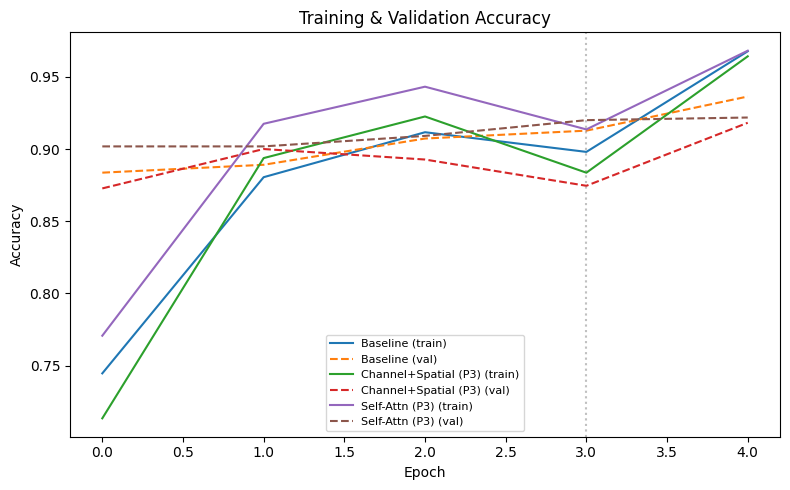

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
to_plot = {'Baseline': 'A0_baseline', 'Channel+Spatial (P3)': 'A3_channel_spatial_P3', 'Self-Attn (P3)': 'A4_self_P3'}
for label, tag in to_plot.items():
    h = HISTORIES[tag]
    ax.plot(h['accuracy'], linestyle='-',  label=f'{label} (train)')
    ax.plot(h['val_accuracy'], linestyle='--', label=f'{label} (val)')
    ax.axvline(h['ft_start_epoch'], color='gray', alpha=0.2, linestyle=':')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.set_title('Training & Validation Accuracy')
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/14_1_accuracy_curves.png', dpi=150); plt.show()


### 14.2 Training/Validation Loss curves

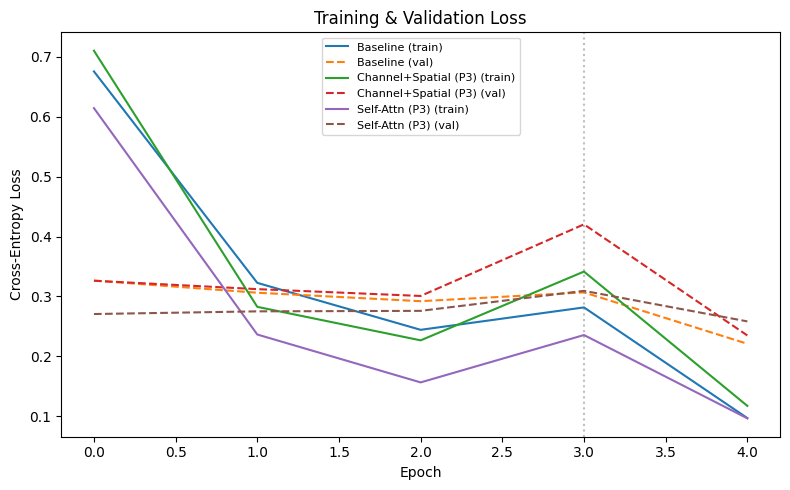

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, tag in to_plot.items():
    h = HISTORIES[tag]
    ax.plot(h['loss'], linestyle='-',  label=f'{label} (train)')
    ax.plot(h['val_loss'], linestyle='--', label=f'{label} (val)')
    ax.axvline(h['ft_start_epoch'], color='gray', alpha=0.2, linestyle=':')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-Entropy Loss'); ax.set_title('Training & Validation Loss')
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/14_2_loss_curves.png', dpi=150); plt.show()


### 14.3 Attention Mechanism vs. Accuracy

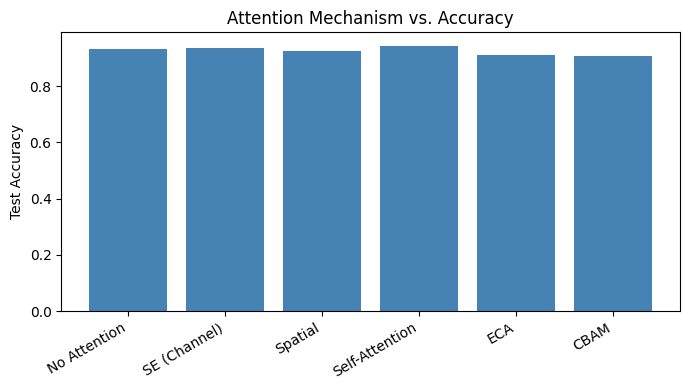

In [37]:
bar_df = df_mechanisms.copy()
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(bar_df['mechanism'], bar_df['accuracy'], color='steelblue')
ax.set_ylabel('Test Accuracy'); ax.set_title('Attention Mechanism vs. Accuracy')
plt.xticks(rotation=30, ha='right'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/14_3_mechanism_vs_accuracy.png', dpi=150); plt.show()


### 14.4 Attention Mechanism vs. Macro F1

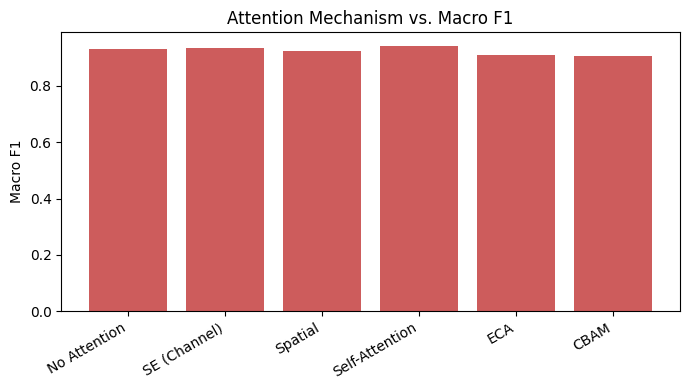

In [38]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(bar_df['mechanism'], bar_df['macro_f1'], color='indianred')
ax.set_ylabel('Macro F1'); ax.set_title('Attention Mechanism vs. Macro F1')
plt.xticks(rotation=30, ha='right'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/14_4_mechanism_vs_f1.png', dpi=150); plt.show()


### 14.5 Accuracy vs. Model Parameters (Accuracy–Complexity Trade-off)

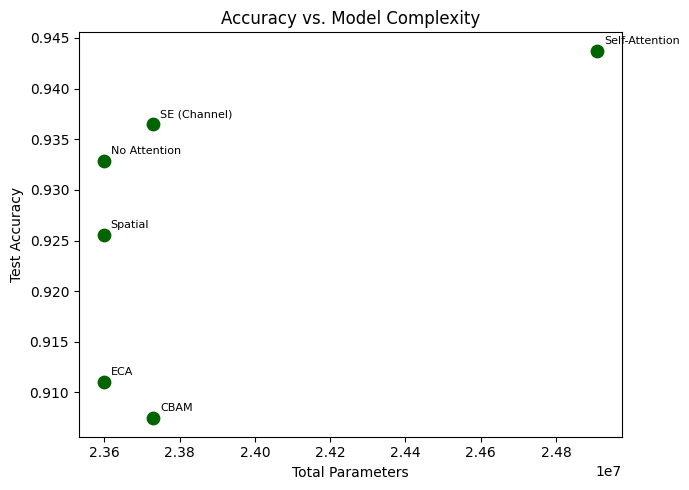

In [39]:
fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(bar_df['total_params'], bar_df['accuracy'], s=80, color='darkgreen')
for _, row in bar_df.iterrows():
    ax.annotate(row['mechanism'], (row['total_params'], row['accuracy']), fontsize=8,
                xytext=(5,5), textcoords='offset points')
ax.set_xlabel('Total Parameters'); ax.set_ylabel('Test Accuracy')
ax.set_title('Accuracy vs. Model Complexity'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/14_5_accuracy_vs_params.png', dpi=150); plt.show()


### 14.6 Macro F1 vs. Inference Time

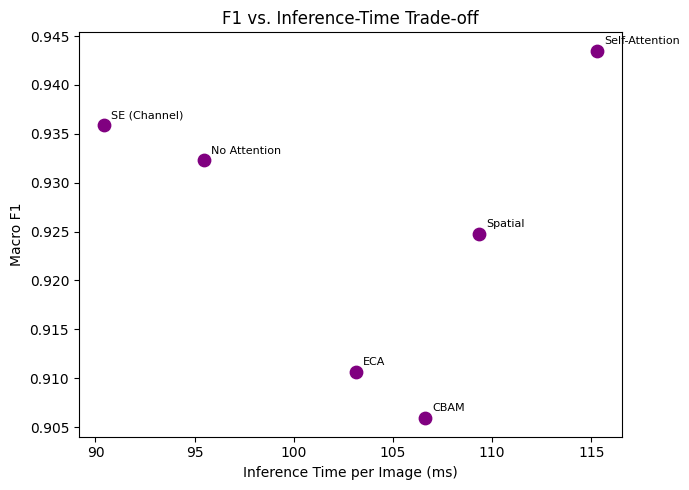

In [40]:
fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(bar_df['inference_time_ms'], bar_df['macro_f1'], s=80, color='purple')
for _, row in bar_df.iterrows():
    ax.annotate(row['mechanism'], (row['inference_time_ms'], row['macro_f1']), fontsize=8,
                xytext=(5,5), textcoords='offset points')
ax.set_xlabel('Inference Time per Image (ms)'); ax.set_ylabel('Macro F1')
ax.set_title('F1 vs. Inference-Time Trade-off'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/14_6_f1_vs_inference_time.png', dpi=150); plt.show()


## 15. Confusion Matrix Analysis (Sec. 25)

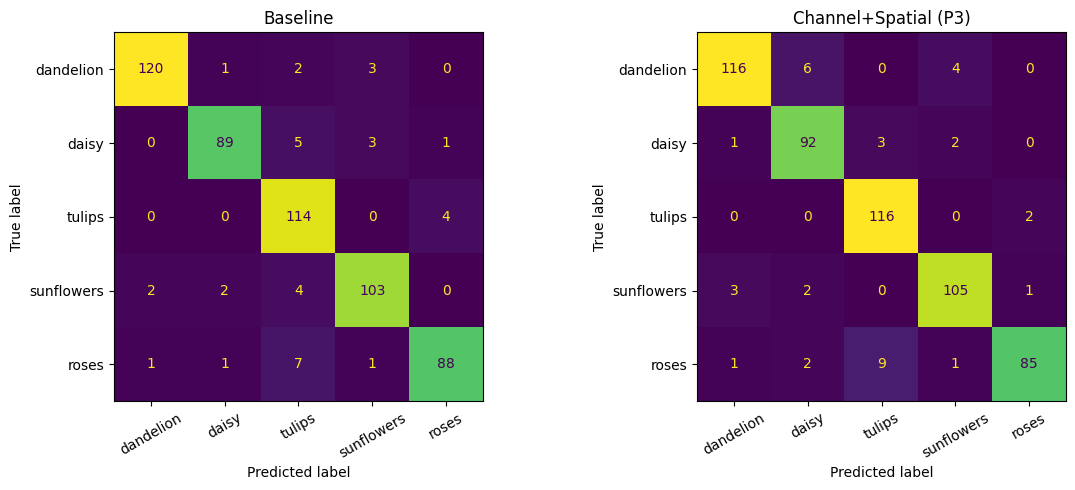

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, tag, title in zip(axes, ['A0_baseline', 'A3_channel_spatial_P3'], ['Baseline', 'Channel+Spatial (P3)']):
    y_true, y_pred = PREDICTIONS[tag]
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(title)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/15_confusion_matrices.png', dpi=150); plt.show()


## 16. Qualitative Analysis — Grad-CAM (Sec. 26–27)

In [42]:
def grad_cam(model, img_array, last_conv_layer_name, class_index=None):
    """Standard Grad-CAM w.r.t. the model's final convolutional feature map."""
    grad_model = keras.Model(model.input, [model.get_layer(last_conv_layer_name).output, model.output]) \
        if last_conv_layer_name in [l.name for l in model.layers] else None
    if grad_model is None:
        # locate the last 4D (spatial) tensor layer by walking the graph
        for layer in reversed(model.layers):
            if len(layer.output_shape) == 4:
                last_conv_layer_name = layer.name
                break
        grad_model = keras.Model(model.input, [model.get_layer(last_conv_layer_name).output, model.output])

    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array)
        if class_index is None:
            class_index = tf.argmax(preds[0])
        class_score = preds[:, class_index]
    grads = tape.gradient(class_score, conv_out)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out = conv_out[0]
    heatmap = tf.reduce_sum(conv_out * pooled_grads, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(class_index.numpy())

def overlay_heatmap(image_uint8, heatmap, alpha=0.4):
    heatmap_resized = tf.image.resize(heatmap[..., None], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
    heatmap_color = plt.cm.jet(heatmap_resized)[..., :3]
    overlay = (1 - alpha) * (image_uint8 / 255.0) + alpha * heatmap_color
    return np.clip(overlay, 0, 1)


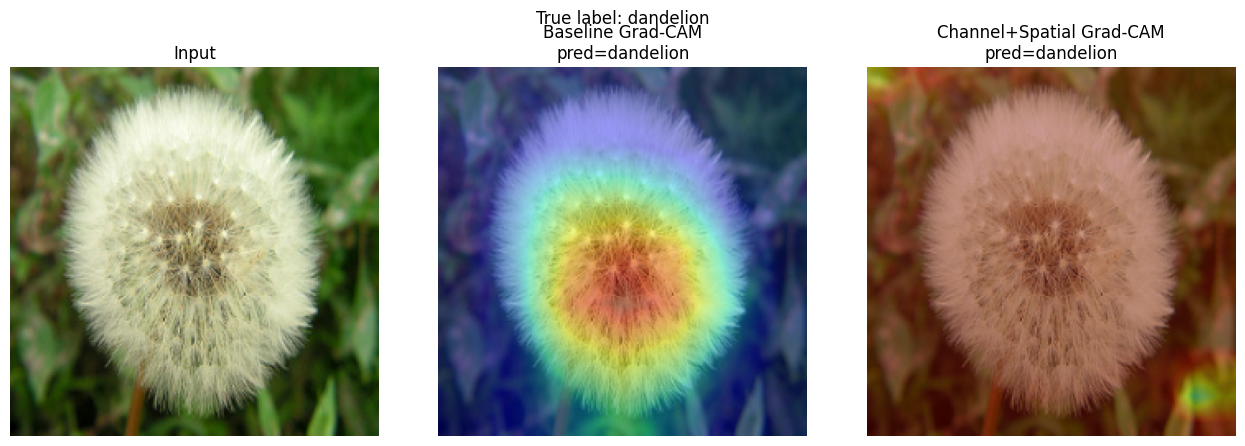

In [43]:
def grad_cam(model, img_array, last_conv_layer_name=None, class_index=None):

    def get_layer_recursive(m, name):
        try:
            return m.get_layer(name)
        except ValueError:
            for layer in m.layers:
                if isinstance(layer, keras.Model):
                    found = get_layer_recursive(layer, name)
                    if found is not None:
                        return found
        return None

    target_layer = get_layer_recursive(
        model,
        last_conv_layer_name
    )

    if target_layer is None:
        raise ValueError(
            f"Could not find layer '{last_conv_layer_name}' in model."
        )

    activation = {}

    original_call = target_layer.call

    def hooked_call(*args, **kwargs):
        output = original_call(*args, **kwargs)
        activation["value"] = output
        return output

    target_layer.call = hooked_call

    try:

        with tf.GradientTape() as tape:

            preds = model(
                img_array,
                training=False
            )

            conv_out = activation.get("value")

            if conv_out is None:
                raise ValueError(
                    f"Target layer '{last_conv_layer_name}' "
                    f"was not executed during the forward pass."
                )

            if class_index is None:
                class_index = tf.argmax(
                    preds[0]
                )

            class_score = preds[:, class_index]

        grads = tape.gradient(
            class_score,
            conv_out
        )

    finally:
        target_layer.call = original_call

    if grads is None:
        raise ValueError(
            f"Could not compute gradients for "
            f"'{last_conv_layer_name}'."
        )

    # ---------------------------------------------------------
    # Handle possible list/tuple outputs
    # ---------------------------------------------------------

    if isinstance(conv_out, (list, tuple)):
        conv_out = conv_out[0]

    if isinstance(grads, (list, tuple)):
        grads = grads[0]

    # ---------------------------------------------------------
    # Grad-CAM
    # ---------------------------------------------------------

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_out = conv_out[0]

    heatmap = tf.reduce_sum(
        conv_out * pooled_grads,
        axis=-1
    )

    heatmap = tf.nn.relu(
        heatmap
    )

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return (
        heatmap.numpy(),
        int(class_index.numpy())
    )


# =============================================================
# Select test image
# =============================================================

sample_img, sample_label = None, None

for img, label in test_raw.take(50):

    sample_img = img.numpy()
    sample_label = int(label.numpy())

    break


# =============================================================
# Prepare image
# =============================================================

img_resized = tf.image.resize(
    sample_img,
    (IMG_SIZE, IMG_SIZE)
).numpy()

img_input = keras.applications.resnet50.preprocess_input(
    img_resized.copy()
)[None, ...]


# =============================================================
# Load baseline model
# =============================================================

model_A0, _ = build_model(
    attn_spec={},
    name="A0_baseline"
)

model_A0.load_weights(
    _ckpt_paths("A0_baseline")["model"]
)


# =============================================================
# Load attention model
# =============================================================

model_A3, _ = build_model(
    attn_spec={
        "P3": "channel_spatial"
    },
    name="A3_channel_spatial_P3"
)

model_A3.load_weights(
    _ckpt_paths("A3_channel_spatial_P3")["model"]
)


# =============================================================
# Baseline Grad-CAM
# =============================================================

heatmap_base, pred_base = grad_cam(
    model_A0,
    img_input,
    last_conv_layer_name="conv5_block3_out"
)


# =============================================================
# Channel + Spatial Attention Grad-CAM
# =============================================================

heatmap_attn, pred_attn = grad_cam(
    model_A3,
    img_input,
    last_conv_layer_name=(
        "A3_channel_spatial_P3_P3_channel_spatial_sp_conv"
    )
)


# =============================================================
# Visualization
# =============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4.5)
)


axes[0].imshow(
    img_resized.astype("uint8")
)

axes[0].set_title(
    "Input"
)

axes[0].axis("off")


axes[1].imshow(
    overlay_heatmap(
        img_resized,
        heatmap_base
    )
)

axes[1].set_title(
    f"Baseline Grad-CAM\npred={CLASS_NAMES[pred_base]}"
)

axes[1].axis("off")


axes[2].imshow(
    overlay_heatmap(
        img_resized,
        heatmap_attn
    )
)

axes[2].set_title(
    f"Channel+Spatial Grad-CAM\npred={CLASS_NAMES[pred_attn]}"
)

axes[2].axis("off")


plt.suptitle(
    f"True label: {CLASS_NAMES[sample_label]}"
)

plt.tight_layout()

plt.savefig(
    f"{OUT_DIR}/figures/16_gradcam_comparison.png",
    dpi=150
)

plt.show()

## 17. Internal Attention-Map Visualizations (Sec. 28)

### 17.1 Channel-attention weights (top-K bar chart)

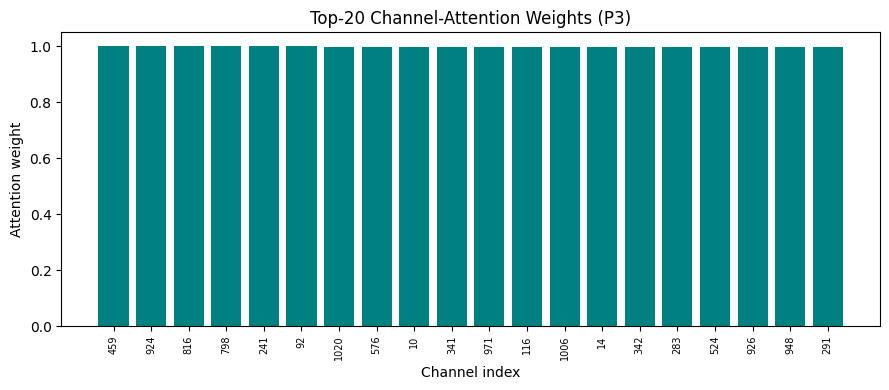

In [44]:
tag = 'A1_channel_P3'
attn_info = ATTN_TENSORS[tag]['P3']
ch_map_model = keras.Model(model_A1.input, model_A1.get_layer(attn_info['map_layer']).output)
ch_weights = ch_map_model.predict(img_input, verbose=0).reshape(-1)
K = 20
top_idx = np.argsort(ch_weights)[::-1][:K]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(K), ch_weights[top_idx], color='teal')
ax.set_xticks(range(K)); ax.set_xticklabels(top_idx, rotation=90, fontsize=7)
ax.set_xlabel('Channel index'); ax.set_ylabel('Attention weight')
ax.set_title(f'Top-{K} Channel-Attention Weights (P3)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/17_1_channel_attention_weights.png', dpi=150); plt.show()


### 17.2 Spatial-attention heatmap & overlay

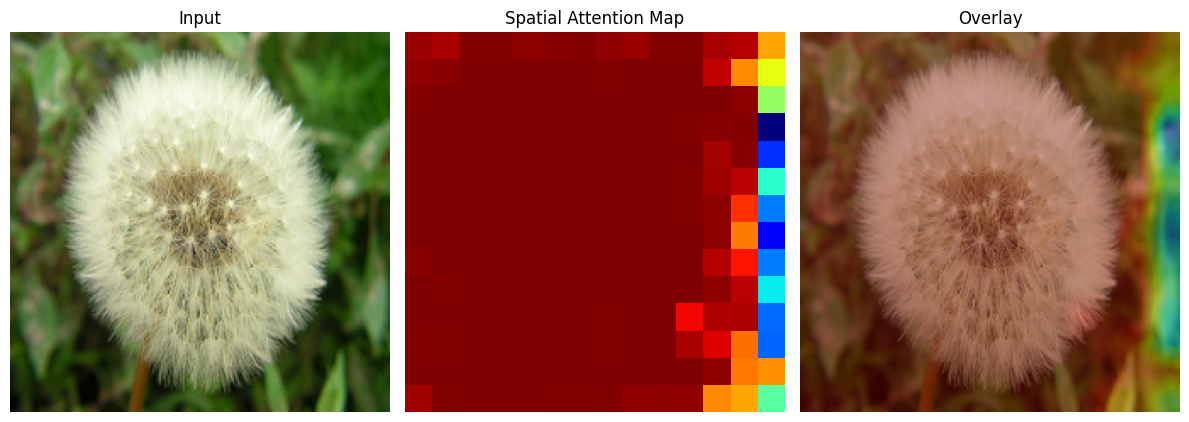

In [45]:
tag = 'A2_spatial_P3'

model_A2, _ = build_model(
    attn_spec={'P3': 'spatial'},
    name='A2_spatial_P3'
)

model_A2.load_weights(
    _ckpt_paths('A2_spatial_P3')['model']
)

sp_info = ATTN_TENSORS[tag]['P3']

sp_map_model = keras.Model(
    inputs=model_A2.input,
    outputs=model_A2.get_layer(
        sp_info['map_layer']
    ).output
)

sp_map = sp_map_model.predict(
    img_input,
    verbose=0
)[0, ..., 0]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 4.5)
)

axes[0].imshow(
    img_resized.astype('uint8')
)
axes[0].set_title('Input')
axes[0].axis('off')

axes[1].imshow(
    sp_map,
    cmap='jet'
)
axes[1].set_title('Spatial Attention Map')
axes[1].axis('off')

axes[2].imshow(
    overlay_heatmap(
        img_resized,
        sp_map
    )
)
axes[2].set_title('Overlay')
axes[2].axis('off')

plt.tight_layout()

plt.savefig(
    f'{OUT_DIR}/figures/17_2_spatial_attention.png',
    dpi=150
)

plt.show()

### 17.3 Self-attention response

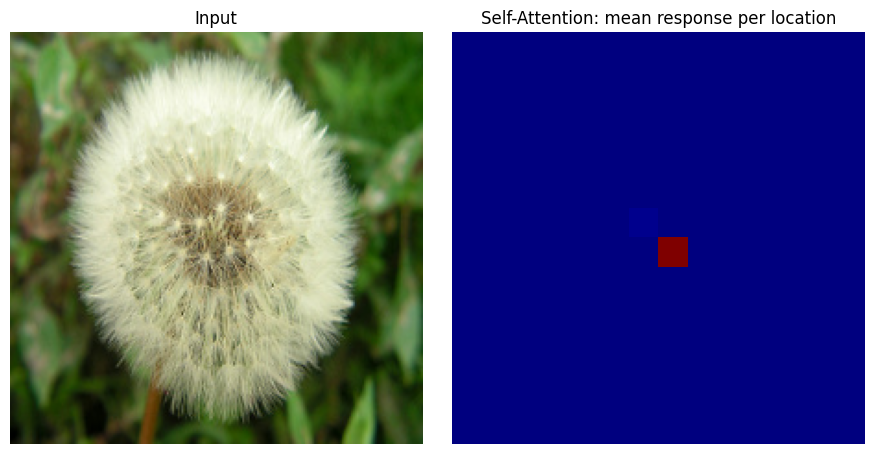

In [46]:
tag = 'A4_self_P3'
self_info = ATTN_TENSORS[tag]['P3']
self_layer = model_A4.get_layer(self_info['self_attn_layer'])
self_attn_model = keras.Model(model_A4.input, self_layer.output[self_info['self_attn_output_index']])
attn_matrix = self_attn_model.predict(img_input, verbose=0)[0]     # (N, N)
mean_attn = attn_matrix.mean(axis=0)                                 # mean attention received by each location
side = int(np.sqrt(mean_attn.shape[0]))
mean_attn_2d = mean_attn.reshape(side, side)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(img_resized.astype('uint8')); axes[0].set_title('Input'); axes[0].axis('off')
axes[1].imshow(mean_attn_2d, cmap='jet'); axes[1].set_title('Self-Attention: mean response per location'); axes[1].axis('off')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/17_3_self_attention_response.png', dpi=150); plt.show()


### 17.4 Feature maps before / after attention (sample channel slices, Required Visualization #5/#10)

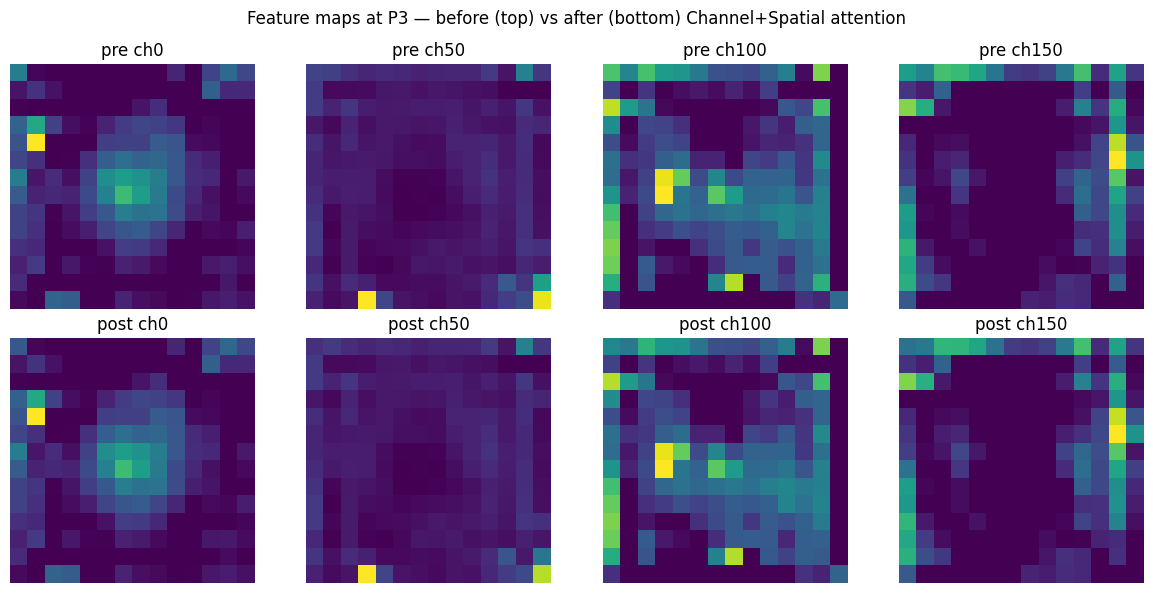

In [47]:
# Tap the P3 pre-attention tensor using model_A3's OWN stashed stage submodels
# (each model builds and keeps its own backbone — see Section 4 — rather than a global one).
sm = model_A3.stage_submodels
x0 = model_A3.input
x1 = sm[0](x0)
x2 = sm[1](x1)
x3_pre = sm[2](x2)   # P3 feature BEFORE attention
pre_feat_model = keras.Model(x0, x3_pre)
pre_feat = pre_feat_model.predict(img_input, verbose=0)[0]

# Post-attention P3 feature: locate the multiply output inside model_A3 at P3
post_layer = [l for l in model_A3.layers if l.name.endswith('_sp_scale')][0]
post_feat_model = keras.Model(model_A3.input, post_layer.output)
post_feat = post_feat_model.predict(img_input, verbose=0)[0]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(pre_feat[..., i*50], cmap='viridis'); axes[0, i].axis('off')
    axes[0, i].set_title(f'pre ch{i*50}')
    axes[1, i].imshow(post_feat[..., i*50], cmap='viridis'); axes[1, i].axis('off')
    axes[1, i].set_title(f'post ch{i*50}')
plt.suptitle('Feature maps at P3 — before (top) vs after (bottom) Channel+Spatial attention')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/17_4_feature_maps_pre_post.png', dpi=150); plt.show()


## 18. Attention Position Visualization — same image at P2/P3/P4 (Sec. 29)

Rebuilding model structure and loading weights for B2_cs_P2...
Rebuilding model structure and loading weights for B4_cs_P4...


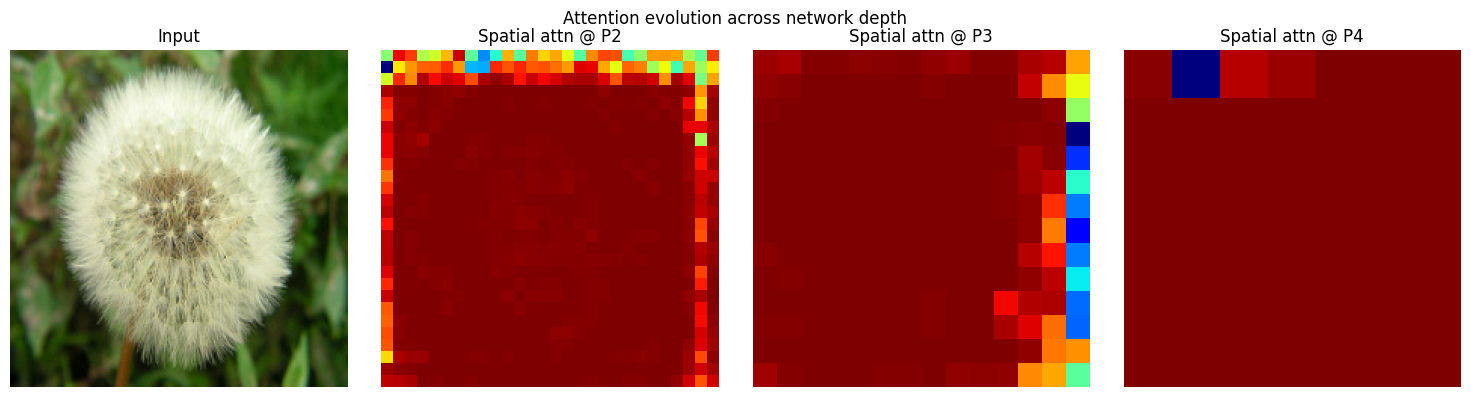

In [51]:
# =============================================================
# Models by position (Reloaded robustly from checkpoints if freed)
# =============================================================

models_by_pos = {
    'P2': model_B2,
    'P3': model_A2,
    'P4': model_B4
}

# Ensure all models are loaded from checkpoints if they were freed
for pos, tag in [('P2', 'B2_cs_P2'), ('P3', 'A2_spatial_P3'), ('P4', 'B4_cs_P4')]:
    if models_by_pos[pos] is None:
        # Skip using keras.models.load_model due to Lambda serialization bugs in Keras
        print(f"Rebuilding model structure and loading weights for {tag}...")
        if pos == 'P2':
            mdl, _ = build_model(attn_spec={'P2': 'channel_spatial'}, name=tag)
        elif pos == 'P3':
            mdl, _ = build_model(attn_spec={'P3': 'spatial'}, name=tag)
        elif pos == 'P4':
            mdl, _ = build_model(attn_spec={'P4': 'channel_spatial'}, name=tag)
        mdl.load_weights(_ckpt_paths(tag)['model'])
        models_by_pos[pos] = mdl

# =============================================================
# Correct ATTN_TENSORS tags
# =============================================================

attention_tags = {
    'P2': 'B2_cs_P2',
    'P3': 'A2_spatial_P3',
    'P4': 'B4_cs_P4'
}


# =============================================================
# Extract spatial attention maps
# =============================================================

maps = {}

for pos in ['P2', 'P3', 'P4']:
    mdl = models_by_pos[pos]
    tag = attention_tags[pos]

    info = ATTN_TENSORS[tag][pos]

    layer_name = info.get(
        'spatial_map_layer',
        info.get('map_layer')
    )

    tap = keras.Model(
        inputs=mdl.input,
        outputs=mdl.get_layer(layer_name).output
    )

    maps[pos] = tap.predict(
        img_input,
        verbose=0
    )[0, ..., 0]


# =============================================================
# Visualization
# =============================================================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(15, 4)
)

axes[0].imshow(
    img_resized.astype('uint8')
)

axes[0].set_title('Input')
axes[0].axis('off')


for ax, pos in zip(
    axes[1:],
    ['P2', 'P3', 'P4']
):
    ax.imshow(
        maps[pos],
        cmap='jet'
    )

    ax.set_title(
        f'Spatial attn @ {pos}'
    )

    ax.axis('off')


plt.suptitle(
    'Attention evolution across network depth'
)

plt.tight_layout()

plt.savefig(
    f'{OUT_DIR}/figures/18_attention_by_position.png',
    dpi=150
)

plt.show()

## 19. Qualitative Comparison Across Models — multiple images (Sec. 30)
3 correctly-classified + 2 incorrectly-classified test images, compared across baseline / channel+spatial / self-attention Grad-CAMs.

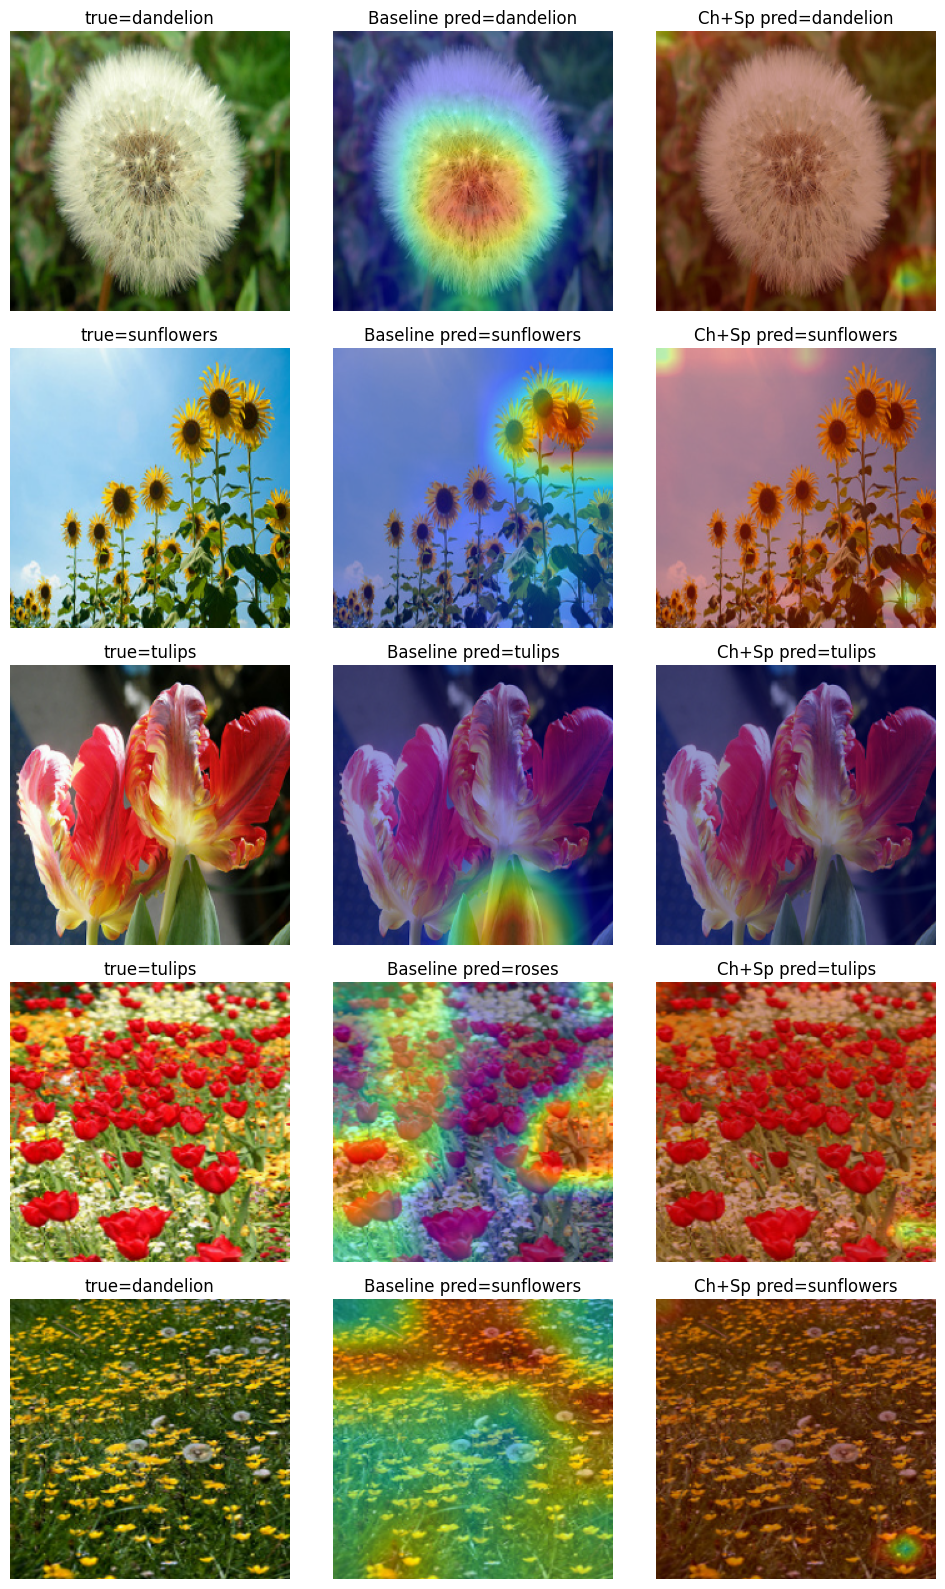

In [53]:
y_true_base, y_pred_base = PREDICTIONS['A0_baseline']
correct_idx = np.where(y_true_base == y_pred_base)[0][:3]
incorrect_idx = np.where(y_true_base != y_pred_base)[0][:2]
chosen_idx = np.concatenate([correct_idx, incorrect_idx])

test_images_list = list(test_raw.as_numpy_iterator())

fig, axes = plt.subplots(len(chosen_idx), 3, figsize=(10, 3.2*len(chosen_idx)))
for row, idx in enumerate(chosen_idx):
    raw_img, raw_label = test_images_list[idx]
    img_r = tf.image.resize(raw_img, (IMG_SIZE, IMG_SIZE)).numpy()
    img_in = keras.applications.resnet50.preprocess_input(img_r.copy())[None, ...]
    hm_base, pb = grad_cam(model_A0, img_in, 'conv5_block3_out')
    hm_attn, pa = grad_cam(model_A3, img_in, 'A3_channel_spatial_P3_P3_channel_spatial_sp_conv')
    axes[row, 0].imshow(img_r.astype('uint8')); axes[row, 0].set_title(f'true={CLASS_NAMES[raw_label]}'); axes[row, 0].axis('off')
    axes[row, 1].imshow(overlay_heatmap(img_r, hm_base)); axes[row, 1].set_title(f'Baseline pred={CLASS_NAMES[pb]}'); axes[row, 1].axis('off')
    axes[row, 2].imshow(overlay_heatmap(img_r, hm_attn)); axes[row, 2].set_title(f'Ch+Sp pred={CLASS_NAMES[pa]}'); axes[row, 2].axis('off')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figures/19_qualitative_multi_image.png', dpi=150); plt.show()

## 20. Discussion Prompts (Sec. 37 — Questions Students Must Answer)

Use the quantitative tables (`main_results_df`, `df_exp1`..`df_exp5`, `df_mechanisms`) and the
figures above as evidence for each answer. Suggested places to look:

| Question (abridged) | Evidence to cite |
|---|---|
| Does attention type affect performance? | `df_exp1` |
| Where should attention be inserted? | `df_exp2`, §18 position-map figure |
| Is attention at more locations always better? | `df_exp3` |
| Channel→Spatial vs Spatial→Channel? | `df_exp4` |
| Effect of spatial kernel size? | `df_exp5` |
| Accuracy–complexity trade-off? | §14.5 scatter |
| F1–inference-time trade-off? | §14.6 scatter |
| Internal attention vs. Grad-CAM (post-hoc)? | §16 vs §17 |
| Which classes benefit most / are most confused? | §15 confusion matrices |

Write your narrative answers in the markdown cell below.

### Your written discussion goes here

*(Fill in after running the full — non `QUICK_RUN` — experiments.)*
1. Residual connections…
2. conv2_x vs conv5_x…
3. …


## 21. Save All Results

In [54]:
results_df = pd.DataFrame(RESULTS)
results_df.to_csv(f'{OUT_DIR}/all_experiment_results.csv', index=False)
results_df


,tag,accuracy,precision,recall,macro_f1,trainable_params,total_params,inference_time_ms
0,A0_baseline,0.932849,0.935767,0.930507,0.932277,14986245,23597957,95.455856
1,A1_channel_P3,0.936479,0.936330,0.937676,0.935863,15118405,23730117,90.408607
2,A2_spatial_P3,0.925590,0.930434,0.922319,0.924786,14986344,23598056,109.358296
3,A3_channel_spatial_P3,0.932849,0.934060,0.931151,0.931609,15118504,23730216,96.770973
4,A4_self_P3,0.943739,0.942798,0.944564,0.943505,16298246,24909958,115.301304
5,A5_combined_P3,0.934664,0.937527,0.931903,0.934001,16430505,25042217,97.223735
6,B1_cs_P1,0.909256,0.910197,0.909487,0.908534,14994808,23606520,106.757016
7,B2_cs_P2,0.914701,0.918747,0.914355,0.914026,15019656,23631368,104.275908
8,B4_cs_P4,0.918330,0.920159,0.914657,0.916615,15512808,24124520,105.926776
9,C_cs_P3_P4,0.901996,0.906202,0.903151,0.901322,15645067,24256779,97.220778
